# Does Money Buy Wins? NBA Team Payroll vs. Regular-Season Performance
### Single-season analysis: 1994-95 NBA season (27 teams)
**Author:** Cisse  |  **Phase 3: Jupyter Notebook**

**Research question:** Is a higher team payroll associated with more regular-season wins?

- **H0:** Payroll has no relationship with regular-season wins.
- **H1:** Higher payroll is associated with more wins.

**Data source:** 1994-95 team payrolls from the Dallas Morning News salary list (Jan. 1, 1995), transcribed at eskimo.com/~pbender/misc/salaries95.txt. Wins and playoff results are from the 1994-95 NBA standings.


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import cross_val_predict, cross_val_score, KFold, LeaveOneOut
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, accuracy_score
import warnings; warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(7,4.5)
RNG=42

## 1. Load the data
Columns in `nba_1995_data.csv`:

| column | meaning |
|---|---|
| team | team name |
| payroll | team payroll in dollars (Jan. 1, 1995 salary list) |
| wins | regular-season wins (out of 82) |
| top_salary | highest single-player salary on the team's payroll, in dollars |
| west | 1 if the team is in the Western Conference, 0 if Eastern |
| playoffs | 1 if the team made the playoffs, else 0 |

In [2]:
import os
DATA="nba_1995_data.csv"
df=pd.read_csv(DATA) if os.path.exists(DATA) else pd.DataFrame()
need=["team","payroll","wins","top_salary","west","playoffs"]
REAL = (len(df)>0 and all(c in df.columns for c in need)
        and df[need].notna().all().all())

if REAL:
    DEMO=False
    print(f"Loaded REAL data: {len(df)} teams")
else:
    DEMO=True
    print("="*70)
    print("DEMO MODE: synthetic numbers. NOT real NBA data. Do not submit.")
    print("="*70)
    teams=pd.read_csv(DATA)["team"].tolist() if os.path.exists(DATA) else [f"Team {i+1}" for i in range(27)]
    r=np.random.default_rng(RNG); n=len(teams)
    payroll=r.normal(15e6,3.5e6,n).clip(6e6)
    z=(payroll-payroll.mean())/payroll.std()
    wins=np.round(41+5*z+r.normal(0,9,n)).clip(10,70)
    top=r.normal(4e6,1e6,n).clip(2e6)
    west=r.integers(0,2,n)
    order=np.argsort(-wins); po=np.zeros(n,int); po[order[:16]]=1
    df=pd.DataFrame(dict(team=teams,payroll=payroll,wins=wins,top_salary=top,west=west,playoffs=po))

# put payroll in millions of dollars if it was given in dollars
df["payroll_m"]=np.where(df["payroll"]>1000,df["payroll"]/1e6,df["payroll"])
df["top_salary_m"]=df["top_salary"]/1e6
df["win_pct"]=df["wins"]/82
df.head()

Loaded REAL data: 27 teams


,team,payroll,wins,top_salary,west,playoffs,payroll_m,top_salary_m,win_pct
0,Atlanta Hawks,21869340,42,2747500,0,1,21.869340,2.7475,0.512195
1,Boston Celtics,24462000,35,3300000,0,1,24.462000,3.3000,0.426829
2,Charlotte Hornets,19346658,50,3840000,0,1,19.346658,3.8400,0.609756
3,Chicago Bulls,22053129,47,3850000,0,1,22.053129,3.8500,0.573171
4,Cleveland Cavaliers,28106000,43,4042000,0,1,28.106000,4.0420,0.524390


## 2. Data check

In [3]:
print(df.shape); print(df.isna().sum().sum(),"missing values")
df[["payroll_m","wins","win_pct","top_salary_m"]].describe().round(2)

(27, 9)
0 missing values


,payroll_m,wins,win_pct,top_salary_m
count,27.00,27.00,27.00,27.00
mean,22.18,41.00,0.50,4.22
std,5.34,13.22,0.16,2.35
min,16.26,17.00,0.21,2.61
25%,18.38,31.00,0.38,3.05
50%,21.87,42.00,0.51,3.61
75%,24.27,51.00,0.62,4.13
max,42.07,62.00,0.76,14.66


## Experiment 1: Descriptive statistics and distributions

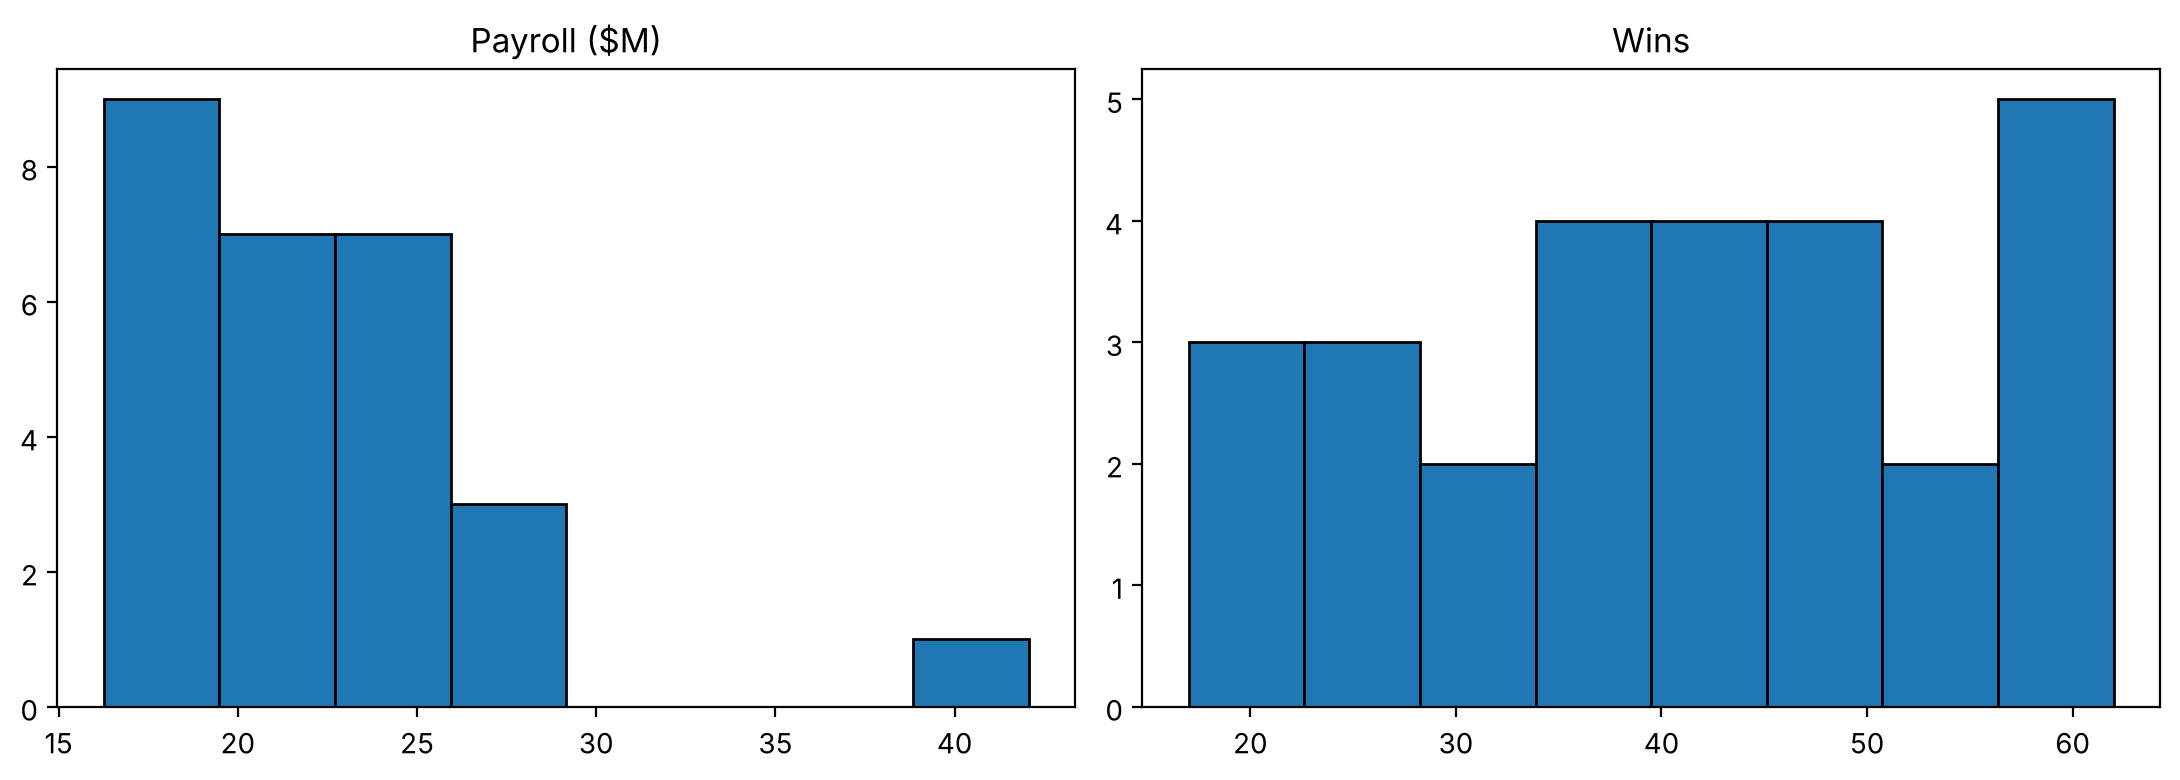

Shapiro-Wilk normality p-values -> payroll: 0.000 | wins: 0.427


In [4]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].hist(df.payroll_m,bins=8,edgecolor="k"); ax[0].set_title("Payroll ($M)")
ax[1].hist(df.wins,bins=8,edgecolor="k"); ax[1].set_title("Wins")
plt.tight_layout(); plt.show()
print("Shapiro-Wilk normality p-values -> payroll: %.3f | wins: %.3f"%(
      stats.shapiro(df.payroll_m)[1], stats.shapiro(df.wins)[1]))

**Interpretation:** *(write 1-2 sentences: are payroll and wins roughly normal? any outliers?)*

## Experiment 2: Correlation (Pearson and Spearman)

Pearson  r = 0.438, p = 0.0223
Spearman rho = 0.549, p = 0.0030


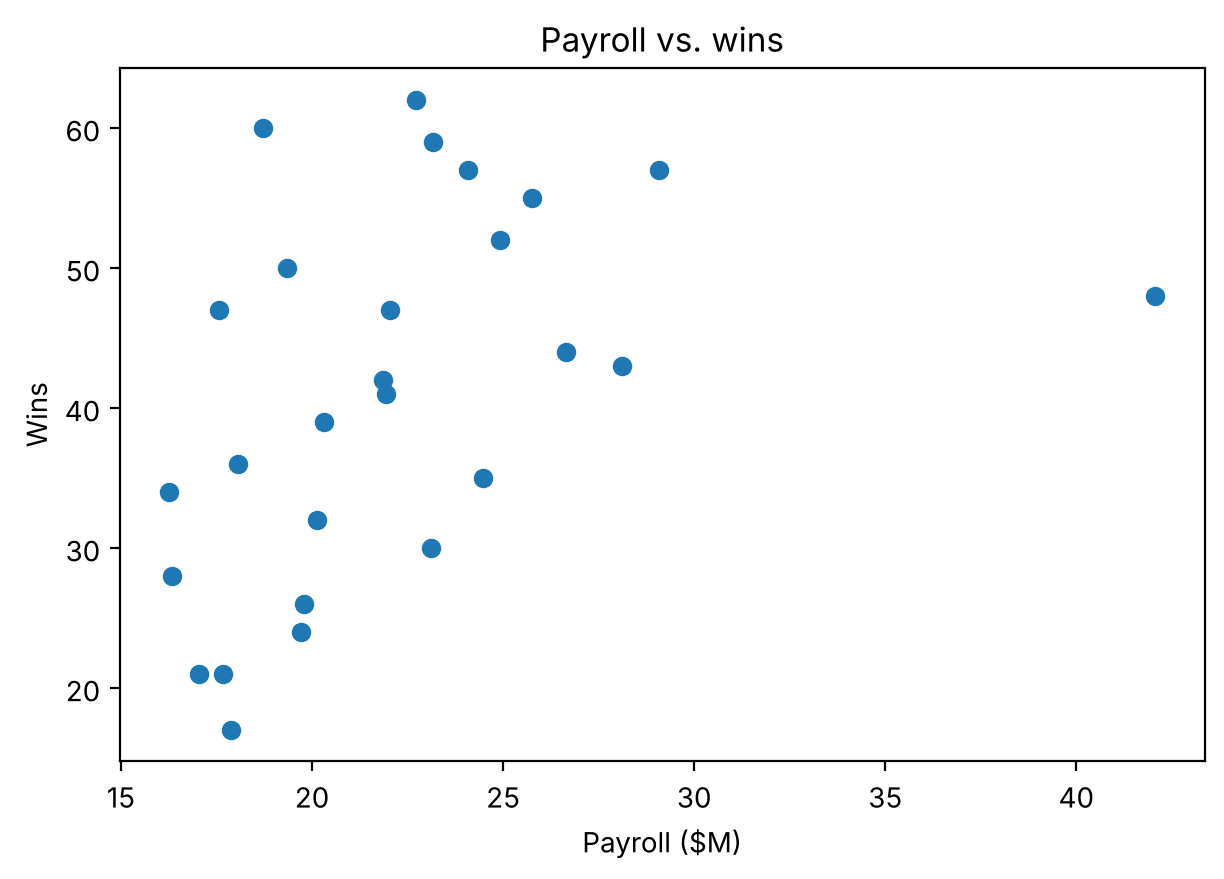

In [5]:
pr,pp=stats.pearsonr(df.payroll_m,df.wins)
sr,sp=stats.spearmanr(df.payroll_m,df.wins)
print(f"Pearson  r = {pr:.3f}, p = {pp:.4f}")
print(f"Spearman rho = {sr:.3f}, p = {sp:.4f}")
plt.scatter(df.payroll_m,df.wins); plt.xlabel("Payroll ($M)"); plt.ylabel("Wins")
plt.title("Payroll vs. wins"); plt.show()

**Interpretation:** *(direction, strength, and whether p < 0.05)*

## Experiment 3: Simple linear regression (wins ~ payroll)

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     16.9545     10.145      1.671      0.107      -3.940      37.849
payroll_m      1.0842      0.445      2.435      0.022       0.167       2.001
R-squared: 0.192


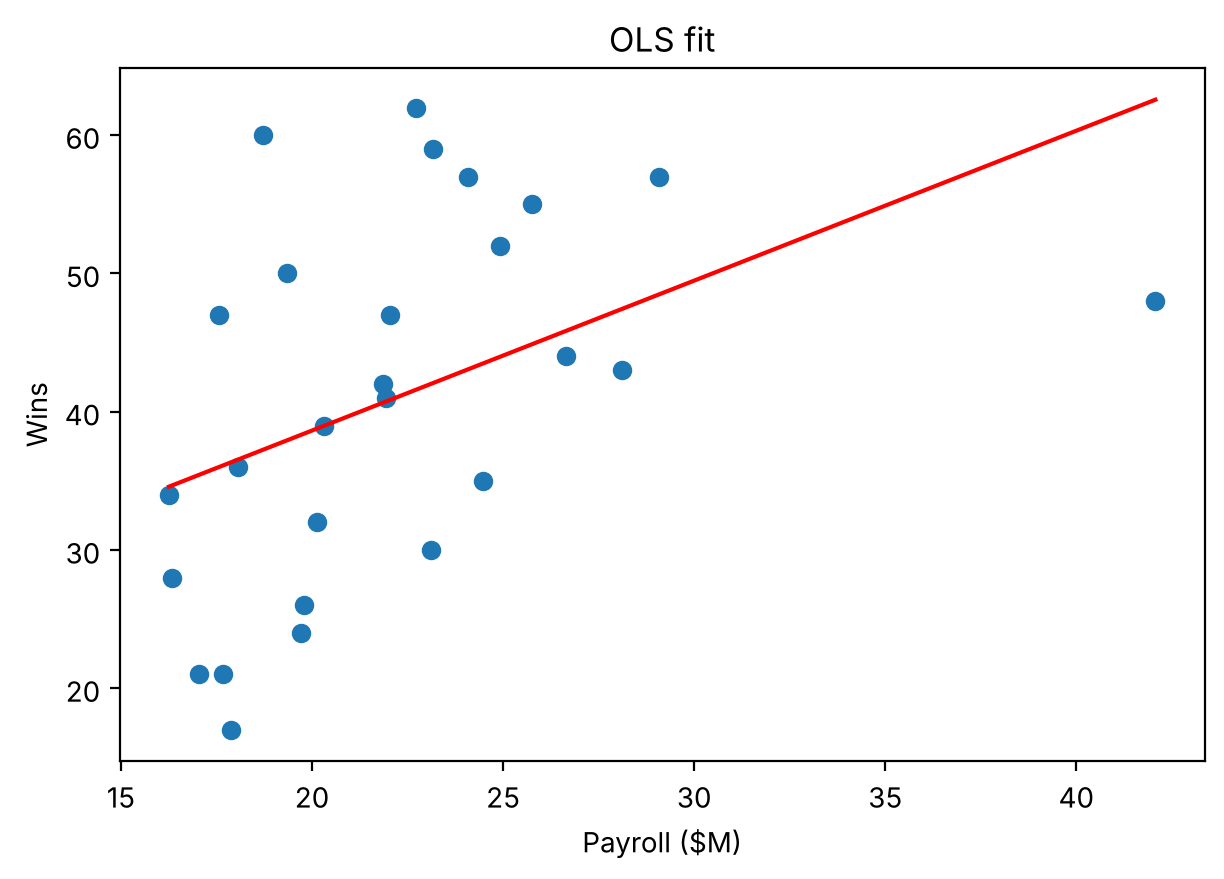

Without the Lakers: slope = 1.994 wins per $1M, R-squared = 0.292, p = 0.0043


In [6]:
m3=smf.ols("wins ~ payroll_m",data=df).fit()
print(m3.summary().tables[1]); print("R-squared:",round(m3.rsquared,3))
x=np.linspace(df.payroll_m.min(),df.payroll_m.max(),50)
plt.scatter(df.payroll_m,df.wins)
plt.plot(x,m3.params["Intercept"]+m3.params["payroll_m"]*x,"r")
plt.xlabel("Payroll ($M)"); plt.ylabel("Wins"); plt.title("OLS fit"); plt.show()

# Sensitivity: the Lakers payroll ($42M) is an outlier driven by retired players
d2=df[df.payroll_m<40]
m3b=smf.ols("wins ~ payroll_m",data=d2).fit()
print("Without the Lakers: slope = %.3f wins per $1M, R-squared = %.3f, p = %.4f"%(m3b.params["payroll_m"],m3b.rsquared,m3b.pvalues["payroll_m"]))

**Interpretation:** *(each extra $1M of payroll is associated with ___ wins; R-squared means ___)*

## Experiment 4: Multiple regression (add top salary and conference)

In [7]:
m4=smf.ols("wins ~ payroll_m + top_salary_m + west",data=df).fit()
print(m4.summary().tables[1])
print("R-squared: %.3f | adj R-squared: %.3f"%(m4.rsquared,m4.rsquared_adj))

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       14.7440     13.410      1.099      0.283     -12.997      42.485
payroll_m        1.1501      0.829      1.387      0.179      -0.566       2.866
top_salary_m    -0.2148      1.955     -0.110      0.913      -4.258       3.829
west             3.4359      5.308      0.647      0.524      -7.544      14.415
R-squared: 0.207 | adj R-squared: 0.104


**Interpretation:** *(does payroll stay significant after controlling for the top salary and conference? Payroll and top salary overlap, so watch for collinearity.)*

## Experiment 5: t-test, high- vs. low-payroll teams (median split)

High-payroll mean win% = 0.591 (n=13)
Low-payroll  mean win% = 0.416 (n=14)
Welch t = 3.360, p = 0.0026


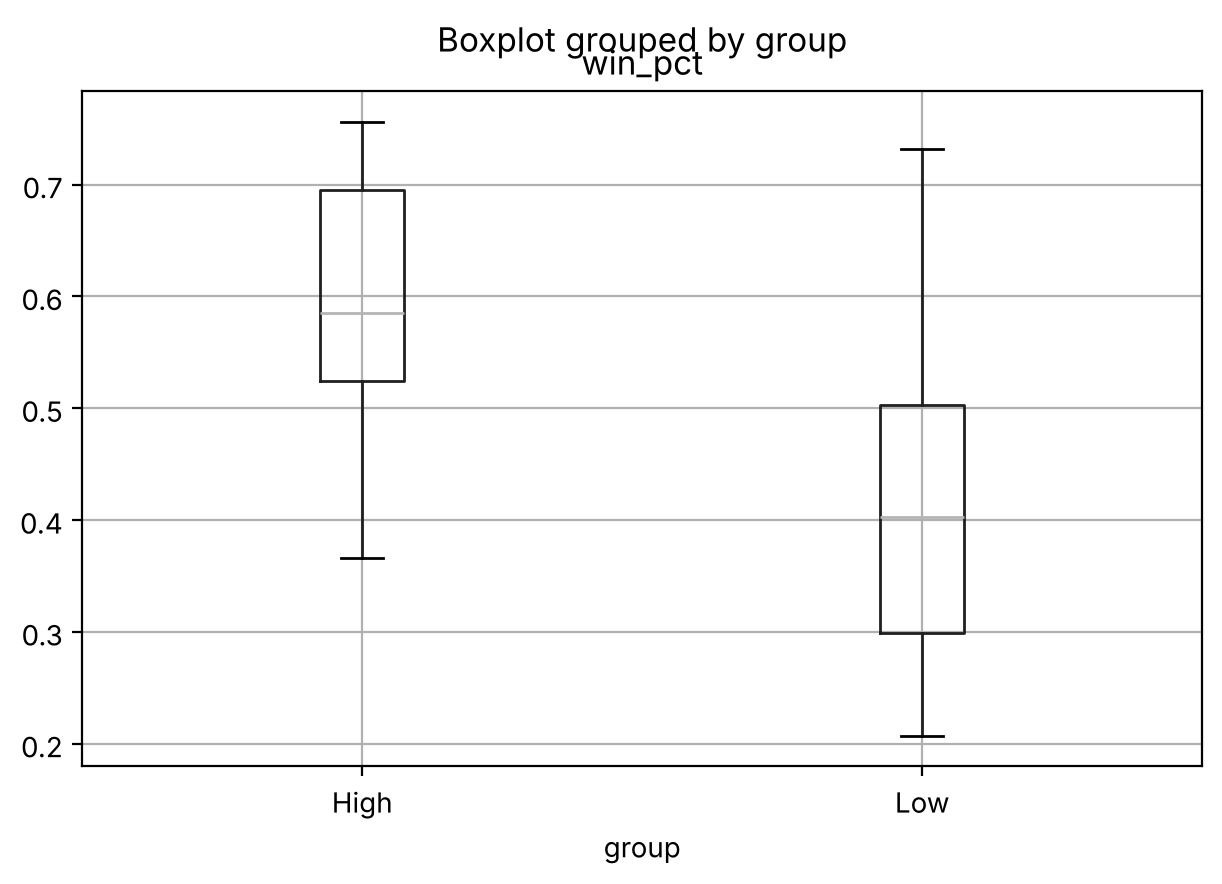

In [8]:
med=df.payroll_m.median()
hi=df[df.payroll_m>med].win_pct; lo=df[df.payroll_m<=med].win_pct
t,p=stats.ttest_ind(hi,lo,equal_var=False)
print(f"High-payroll mean win% = {hi.mean():.3f} (n={len(hi)})")
print(f"Low-payroll  mean win% = {lo.mean():.3f} (n={len(lo)})")
print(f"Welch t = {t:.3f}, p = {p:.4f}")
df.assign(group=np.where(df.payroll_m>med,"High","Low")).boxplot("win_pct","group"); plt.show()

**Interpretation:** *(reject or fail to reject H0, and what that means)*

## Experiment 6: One-way ANOVA across payroll quartiles

          count  mean
quartile             
Q1 low        7  29.1
Q2            7  39.0
Q3            6  49.3
Q4 high       7  47.7
ANOVA F = 4.774, p = 0.0099


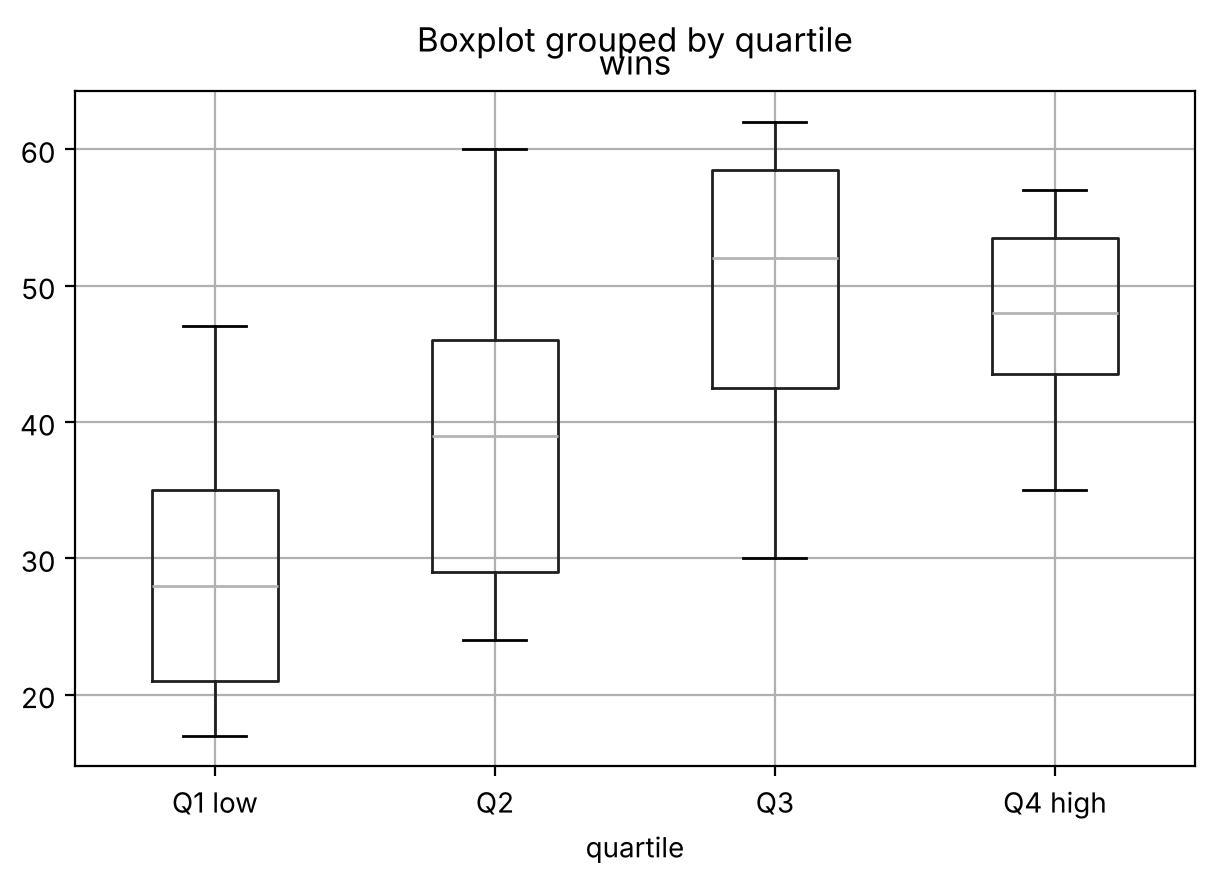

In [9]:
df["quartile"]=pd.qcut(df.payroll_m,4,labels=["Q1 low","Q2","Q3","Q4 high"])
groups=[g.wins.values for _,g in df.groupby("quartile")]
F,p=stats.f_oneway(*groups)
print(df.groupby("quartile").wins.agg(["count","mean"]).round(1))
print(f"ANOVA F = {F:.3f}, p = {p:.4f}")
df.boxplot("wins","quartile"); plt.show()

**Interpretation:** *(do average wins differ across payroll quartiles?)*

## Experiment 7: Diminishing returns (quadratic regression)

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           -46.8723     31.719     -1.478      0.152    -112.337      18.592
payroll_m             6.1235      2.425      2.525      0.019       1.118      11.129
I(payroll_m ** 2)    -0.0923      0.044     -2.109      0.046      -0.183      -0.002


R-squared linear: 0.192 | quadratic: 0.318


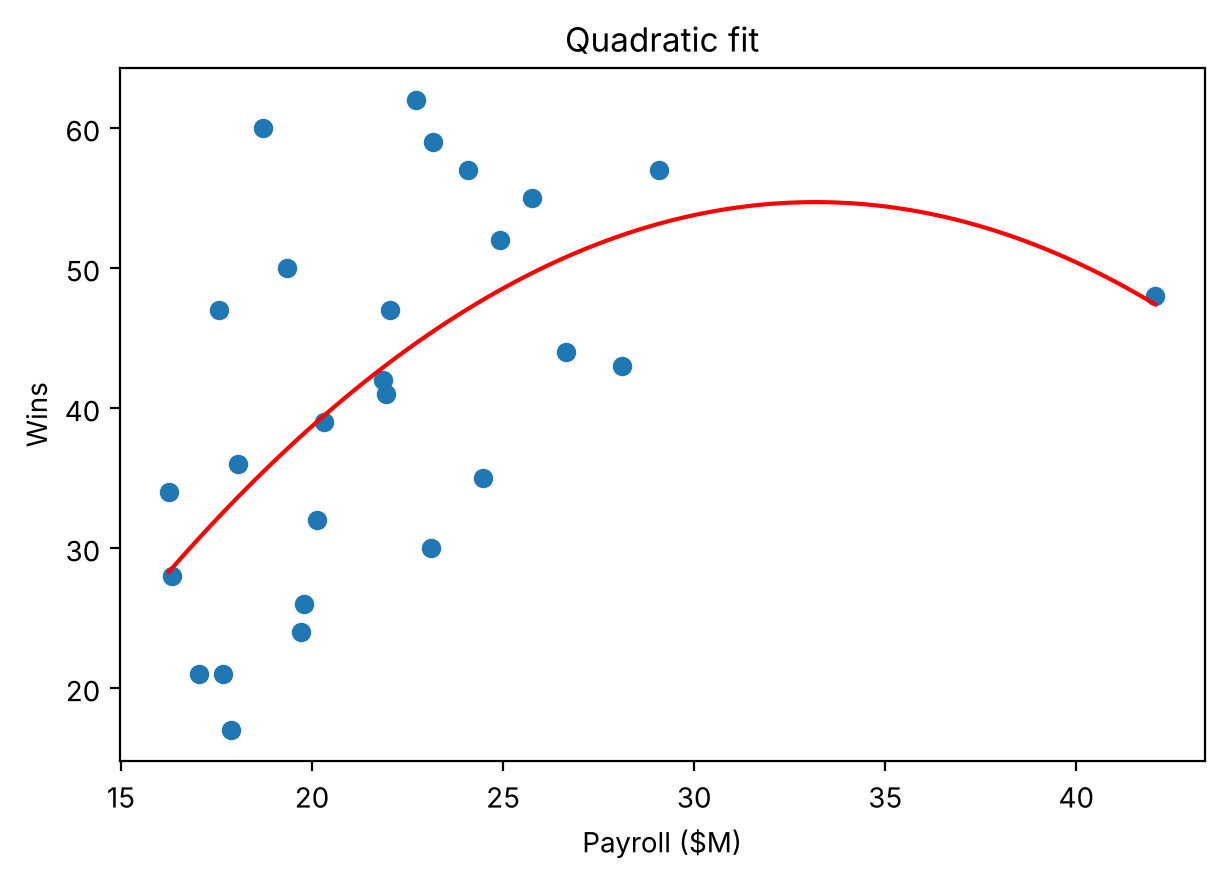

In [10]:
m7=smf.ols("wins ~ payroll_m + I(payroll_m**2)",data=df).fit()
print(m7.summary().tables[1])
print("R-squared linear: %.3f | quadratic: %.3f"%(m3.rsquared,m7.rsquared))
x=np.linspace(df.payroll_m.min(),df.payroll_m.max(),100)
plt.scatter(df.payroll_m,df.wins)
plt.plot(x,m7.predict(pd.DataFrame({"payroll_m":x})),"r")
plt.xlabel("Payroll ($M)"); plt.ylabel("Wins"); plt.title("Quadratic fit"); plt.show()

**Interpretation:** *(is the squared term significant? does extra spending help less at the top?)*

## Experiment 8: Random forest regressor (cross-validated)
With only 27 teams, one train/test split is unreliable, so leave-one-out cross-validation is used.

LOO R-squared: 0.012 | RMSE: 12.90 wins


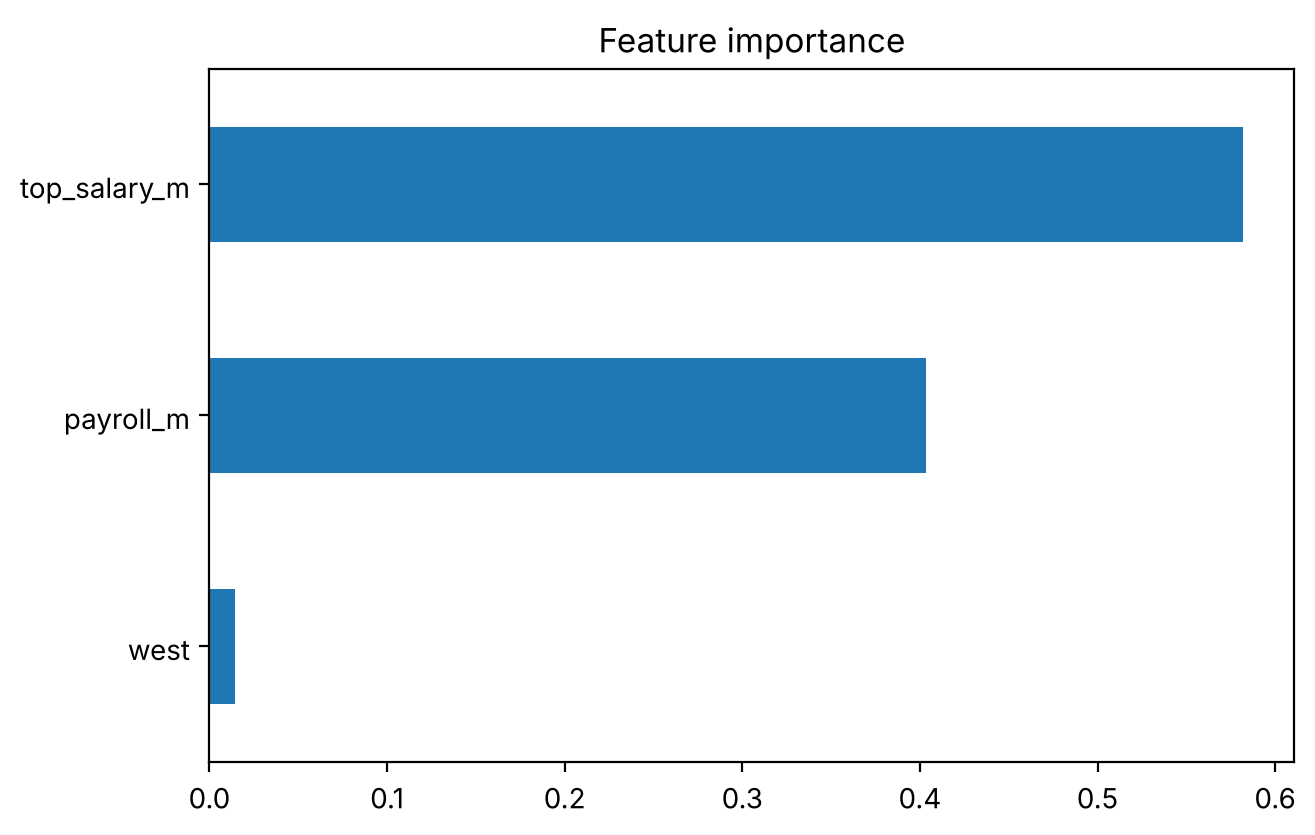

In [11]:
X=df[["payroll_m","top_salary_m","west"]]; y=df.wins
rf=RandomForestRegressor(n_estimators=300,max_depth=3,random_state=RNG)
pred=cross_val_predict(rf,X,y,cv=LeaveOneOut())
print("LOO R-squared: %.3f | RMSE: %.2f wins"%(r2_score(y,pred),np.sqrt(np.mean((y-pred)**2))))
rf.fit(X,y)
pd.Series(rf.feature_importances_,index=X.columns).sort_values().plot.barh(title="Feature importance")
plt.show()

**Interpretation:** *(is the model better than guessing the mean? which feature matters most?)*

## Experiment 9: K-means clustering of teams

         payroll_m   wins
cluster                  
0            23.28  51.14
1            19.23  28.58
2            42.07  48.00


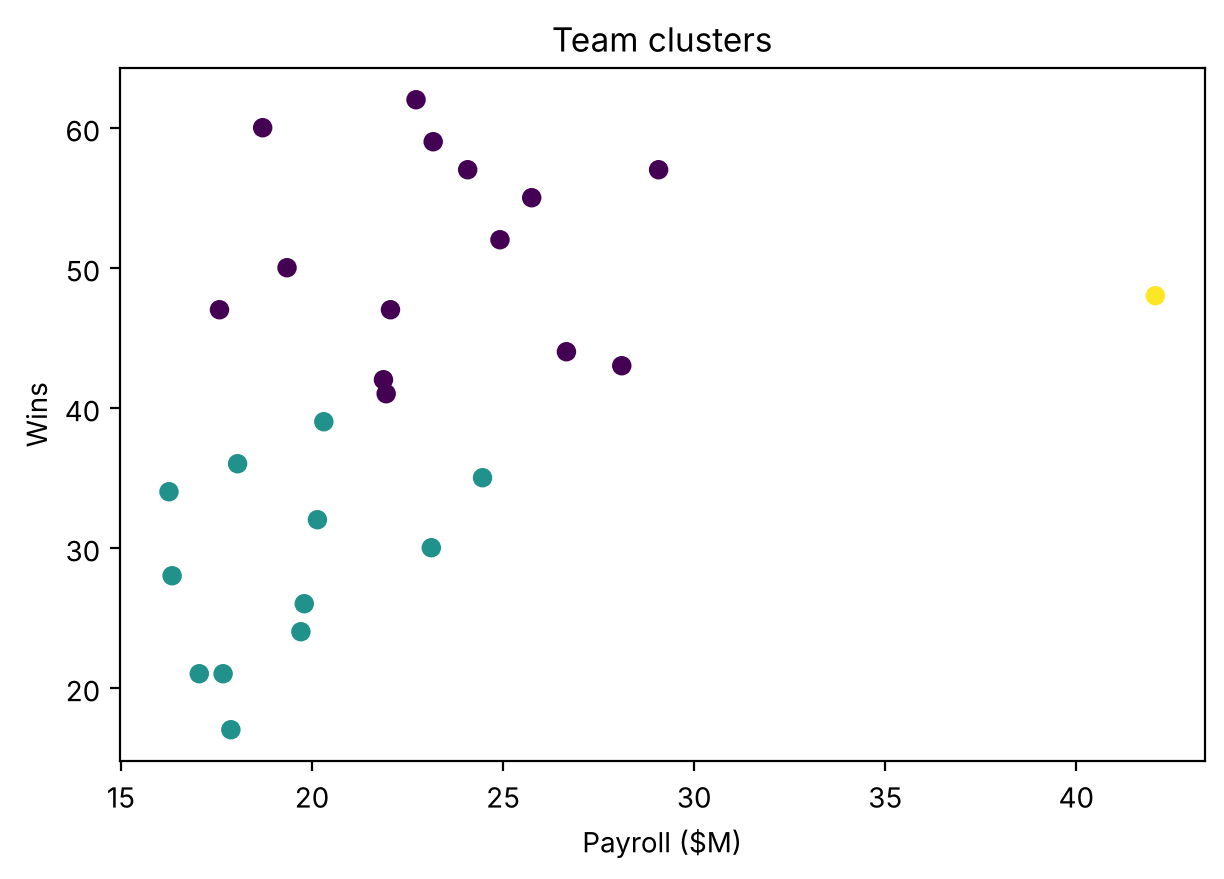

In [12]:
F=StandardScaler().fit_transform(df[["payroll_m","win_pct"]])
km=KMeans(n_clusters=3,n_init=10,random_state=RNG).fit(F)
df["cluster"]=km.labels_
print(df.groupby("cluster")[["payroll_m","wins"]].mean().round(2))
plt.scatter(df.payroll_m,df.wins,c=df.cluster,cmap="viridis")
plt.xlabel("Payroll ($M)"); plt.ylabel("Wins"); plt.title("Team clusters"); plt.show()

**Interpretation:** *(describe each cluster, e.g., high-spend/high-win, low-spend/low-win, overperformers)*

## Experiment 10: Logistic regression, predicting playoff qualification

In [13]:
Xl=df[["payroll_m","top_salary_m"]]; yl=df.playoffs
clf=make_pipeline(StandardScaler(),LogisticRegression())
acc=cross_val_score(clf,Xl,yl,cv=KFold(5,shuffle=True,random_state=RNG),scoring="accuracy")
print("5-fold accuracy: %.3f (+/- %.3f)"%(acc.mean(),acc.std()))
print("Baseline (always predict majority class): %.3f"%max(yl.mean(),1-yl.mean()))
clf.fit(Xl,yl)
print(dict(zip(Xl.columns,clf[-1].coef_[0].round(3))))

5-fold accuracy: 0.773 (+/- 0.088)
Baseline (always predict majority class): 0.593
{'payroll_m': np.float64(1.509), 'top_salary_m': np.float64(0.622)}


**Interpretation:** *(does the model beat the baseline? does higher payroll raise playoff odds?)*

## Summary of results

In [14]:
summary=pd.DataFrame([
 ["1 Descriptive stats","Shapiro-Wilk p (payroll / wins)","%.3f / %.3f"%(stats.shapiro(df.payroll_m)[1],stats.shapiro(df.wins)[1])],
 ["2 Correlation","Pearson r (p)","%.3f (%.4f)"%(pr,pp)],
 ["3 Simple regression","R-squared","%.3f"%m3.rsquared],
 ["4 Multiple regression","Adj. R-squared","%.3f"%m4.rsquared_adj],
 ["5 t-test","Welch p","%.4f"%stats.ttest_ind(hi,lo,equal_var=False)[1]],
 ["6 ANOVA","p","%.4f"%stats.f_oneway(*groups)[1]],
 ["7 Quadratic regression","R-squared","%.3f"%m7.rsquared],
 ["8 Random forest","LOO R-squared","%.3f"%r2_score(y,pred)],
 ["9 K-means","clusters","3"],
 ["10 Logistic regression","CV accuracy","%.3f"%acc.mean()],
],columns=["Experiment","Metric","Value"])
if DEMO: print("DEMO MODE: these numbers are synthetic.\n")
summary

,Experiment,Metric,Value
0,1 Descriptive stats,Shapiro-Wilk p (payroll / wins),0.000 / 0.427
1,2 Correlation,Pearson r (p),0.438 (0.0223)
2,3 Simple regression,R-squared,0.192
3,4 Multiple regression,Adj. R-squared,0.104
4,5 t-test,Welch p,0.0026
5,6 ANOVA,p,0.0099
6,7 Quadratic regression,R-squared,0.318
7,8 Random forest,LOO R-squared,0.012
8,9 K-means,clusters,3
9,10 Logistic regression,CV accuracy,0.773


## Conclusion
*Write 3-5 sentences: Do the results support H1? How strong is the relationship? What else besides payroll affects winning?*

**Limitations**
- One season (n = 27 teams) gives little statistical power. Results may not generalize.
- Payroll comes from a Jan. 1, 1995 newspaper snapshot (Dallas Morning News, transcribed at eskimo.com/~pbender/misc/salaries95.txt) and includes salaries of retired players (e.g., Magic Johnson and James Worthy for the Lakers, Michael Jordan for the Bulls), which inflates some payrolls.
- Market size and attendance data were not available, so conference and top salary are the only controls.
- Correlation does not prove causation.

**Next (Phase 4):** build the Tableau dashboard from these results.